# Initial Data Exploration

In [1]:
import pandas as pd
import numpy as np

df_reviews = pd.read_csv(
    "../data/raw/olist_order_reviews_dataset.csv",
    dtype={
        "review_id": "string",
        "order_id": "string"
    }
)

df_reviews.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [2]:
print("Shape:", df_reviews.shape)

print("\nColumn Information:")
df_reviews.info()

print("\nMissing Values:")
display(df_reviews.isnull().sum())

print("\nDuplicate Rows:", df_reviews.duplicated().sum())

print("\nStatistical Summary:")
display(df_reviews.describe(include="all"))

Shape: (99224, 7)

Column Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   review_id                99224 non-null  string
 1   order_id                 99224 non-null  string
 2   review_score             99224 non-null  int64 
 3   review_comment_title     11568 non-null  object
 4   review_comment_message   40977 non-null  object
 5   review_creation_date     99224 non-null  object
 6   review_answer_timestamp  99224 non-null  object
dtypes: int64(1), object(4), string(2)
memory usage: 5.3+ MB

Missing Values:


review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64


Duplicate Rows: 0

Statistical Summary:


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
count,99224,99224,99224.000000,11568,40977,99224,99224
unique,98410,98673,NaN,4527,36159,636,98248
top,08528f70f579f0c830189efc523d2182,c88b1d1b157a9999ce368f218a407141,NaN,Recomendo,Muito bom,2017-12-19 00:00:00,2017-06-15 23:21:05
freq,3,3,NaN,423,230,463,4
mean,NaN,NaN,4.086421,NaN,NaN,NaN,NaN
std,NaN,NaN,1.347579,NaN,NaN,NaN,NaN
min,NaN,NaN,1.000000,NaN,NaN,NaN,NaN
25%,NaN,NaN,4.000000,NaN,NaN,NaN,NaN
50%,NaN,NaN,5.000000,NaN,NaN,NaN,NaN
75%,NaN,NaN,5.000000,NaN,NaN,NaN,NaN


# Converting date columns 

In [3]:
date_cols = [
    "review_creation_date",
    "review_answer_timestamp"
]

for col in date_cols:
    df_reviews[col] = pd.to_datetime(df_reviews[col])

df_reviews.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   review_id                99224 non-null  string        
 1   order_id                 99224 non-null  string        
 2   review_score             99224 non-null  int64         
 3   review_comment_title     11568 non-null  object        
 4   review_comment_message   40977 non-null  object        
 5   review_creation_date     99224 non-null  datetime64[ns]
 6   review_answer_timestamp  99224 non-null  datetime64[ns]
dtypes: datetime64[ns](2), int64(1), object(2), string(2)
memory usage: 5.3+ MB


# Review score distribution

In [4]:
display(df_reviews["review_score"].value_counts().sort_index())

display(
    df_reviews["review_score"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

review_score
1    11424
2     3151
3     8179
4    19142
5    57328
Name: count, dtype: int64

review_score
1    11.51
2     3.18
3     8.24
4    19.29
5    57.78
Name: proportion, dtype: float64

# Positive vs negative reviews

In [5]:
df_reviews["sentiment"] = np.select(
    [
        df_reviews["review_score"] >= 4,
        df_reviews["review_score"] <= 2
    ],
    ["Positive", "Negative"],
    default="Neutral"
)

display(df_reviews["sentiment"].value_counts())

sentiment
Positive    76470
Negative    14575
Neutral      8179
Name: count, dtype: int64

# Comment availability

In [6]:
print("Reviews with comments:",
      df_reviews["review_comment_message"].notna().sum())

print("Reviews without comments:",
      df_reviews["review_comment_message"].isna().sum())

print("Comment availability percentage:")
display(
    df_reviews["review_comment_message"]
    .notna()
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Reviews with comments: 40977
Reviews without comments: 58247
Comment availability percentage:


review_comment_message
False    58.7
True     41.3
Name: proportion, dtype: float64

# Review trends over time

In [7]:
df_reviews["review_month"] = (
    df_reviews["review_creation_date"].dt.to_period("M")
)

display(df_reviews.groupby("review_month").size())

review_month
2016-10     179
2016-11     101
2016-12      45
2017-01     239
2017-02    1413
2017-03    2481
2017-04    2055
2017-05    3710
2017-06    3440
2017-07    3503
2017-08    4503
2017-09    4199
2017-10    4424
2017-11    4786
2017-12    7982
2018-01    6179
2018-02    6101
2018-03    7803
2018-04    7287
2018-05    7458
2018-06    6715
2018-07    5634
2018-08    8987
Freq: M, dtype: int64

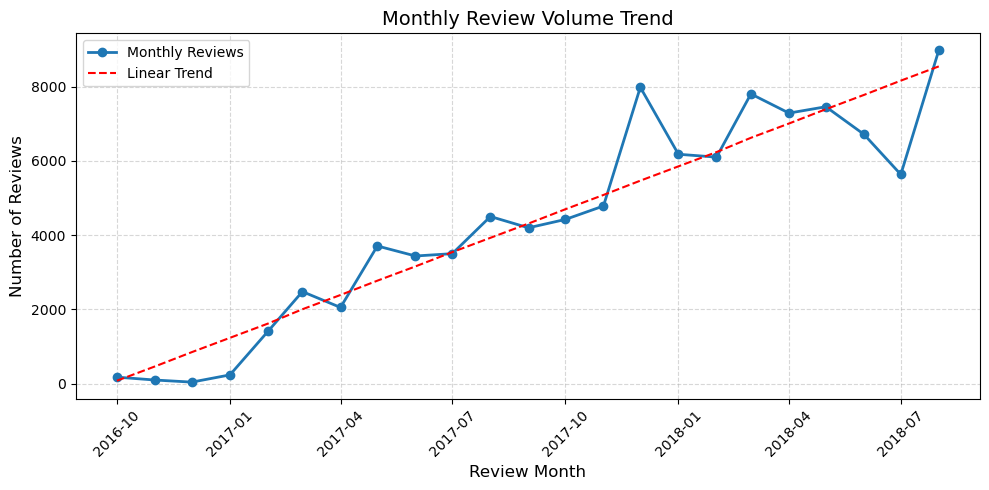

In [8]:
import matplotlib.pyplot as plt 

# 1. Group the data and sort chronologically
monthly_counts = df_reviews.groupby("review_month").size().sort_index()

# 2. Convert PeriodIndex to Timestamp so Matplotlib handles dates cleanly
dates = monthly_counts.index.to_timestamp()
counts = monthly_counts.values

# 3. Create the plot
fig, ax = plt.subplots(figsize=(10, 5))

# Plot the actual monthly review counts
ax.plot(dates, counts, marker="o", linewidth=2, label="Monthly Reviews")

# 4. Calculate and plot a linear trend line (optional)
x_numeric = np.arange(len(dates))
slope, intercept = np.polyfit(x_numeric, counts, 1)
ax.plot(
    dates,
    slope * x_numeric + intercept,
    linestyle="--",
    color="red",
    label="Linear Trend",
)

# 5. Format labels and layout
ax.set_title("Monthly Review Volume Trend", fontsize=14)
ax.set_xlabel("Review Month", fontsize=12)
ax.set_ylabel("Number of Reviews", fontsize=12)
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend()

plt.xticks(rotation=45)
plt.tight_layout()

# Review response time

In [9]:
df_reviews["response_time_hours"] = (
    df_reviews["review_answer_timestamp"]
    - df_reviews["review_creation_date"]
).dt.total_seconds() / 3600

display(df_reviews["response_time_hours"].describe())

count    99224.000000
mean        75.575842
std        237.361183
min          2.141389
25%         24.116875
50%         40.198750
75%         74.485556
max      12448.781111
Name: response_time_hours, dtype: float64

# Duplicate ID investigation

In [10]:
print("Duplicate review IDs:",
      df_reviews["review_id"].duplicated().sum())

print("Duplicate order IDs:",
      df_reviews["order_id"].duplicated().sum())

display(
    df_reviews[df_reviews["review_id"].duplicated(keep=False)]
    .sort_values("review_id")
    .head(10)
)

Duplicate review IDs: 814
Duplicate order IDs: 551


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp,sentiment,review_month,response_time_hours
46678,00130cbe1f9d422698c812ed8ded1919,dfcdfc43867d1c1381bfaf62d6b9c195,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07,2018-03-20 18:08:23,Negative,2018-03,330.139722
29841,00130cbe1f9d422698c812ed8ded1919,04a28263e085d399c97ae49e0b477efa,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07,2018-03-20 18:08:23,Negative,2018-03,330.139722
90677,0115633a9c298b6a98bcbe4eee75345f,78a4201f58af3463bdab842eea4bc801,5,NaN,NaN,2017-09-21,2017-09-26 03:27:47,Positive,2017-09,123.463056
63193,0115633a9c298b6a98bcbe4eee75345f,0c9850b2c179c1ef60d2855e2751d1fa,5,NaN,NaN,2017-09-21,2017-09-26 03:27:47,Positive,2017-09,123.463056
92876,0174caf0ee5964646040cd94e15ac95e,f93a732712407c02dce5dd5088d0f47b,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07,2018-03-08 03:00:53,Negative,2018-03,27.014722
57280,0174caf0ee5964646040cd94e15ac95e,74db91e33b4e1fd865356c89a61abf1f,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07,2018-03-08 03:00:53,Negative,2018-03,27.014722
54832,017808d29fd1f942d97e50184dfb4c13,8daaa9e99d60fbba579cc1c3e3bfae01,5,NaN,NaN,2018-03-02,2018-03-05 01:43:30,Positive,2018-03,73.725000
99167,017808d29fd1f942d97e50184dfb4c13,b1461c8882153b5fe68307c46a506e39,5,NaN,NaN,2018-03-02,2018-03-05 01:43:30,Positive,2018-03,73.725000
20621,0254bd905dc677a6078990aad3331a36,5bf226cf882c5bf4247f89a97c86f273,1,NaN,O pedido consta de 2 produtos e até agora rece...,2017-09-09,2017-09-13 09:52:44,Negative,2017-09,105.878889
96080,0254bd905dc677a6078990aad3331a36,331b367bdd766f3d1cf518777317b5d9,1,NaN,O pedido consta de 2 produtos e até agora rece...,2017-09-09,2017-09-13 09:52:44,Negative,2017-09,105.878889


# Investigate duplicate IDs

In [11]:
# Investigate duplicate review IDs
duplicate_reviews = df_reviews[
    df_reviews["review_id"].duplicated(keep=False)
].sort_values("review_id")

display(duplicate_reviews.head(20))

# Investigate duplicate order IDs
duplicate_orders = df_reviews[
    df_reviews["order_id"].duplicated(keep=False)
].sort_values("order_id")

display(duplicate_orders.head(20))

# Check whether duplicate review IDs have identical review content
review_id_check = (
    df_reviews.groupby("review_id")
    .agg(
        order_count=("order_id", "nunique"),
        score_count=("review_score", "nunique"),
        message_count=("review_comment_message", "nunique")
    )
)

display(review_id_check.describe())

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp,sentiment,review_month,response_time_hours
46678,00130cbe1f9d422698c812ed8ded1919,dfcdfc43867d1c1381bfaf62d6b9c195,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07,2018-03-20 18:08:23,Negative,2018-03,330.139722
29841,00130cbe1f9d422698c812ed8ded1919,04a28263e085d399c97ae49e0b477efa,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07,2018-03-20 18:08:23,Negative,2018-03,330.139722
90677,0115633a9c298b6a98bcbe4eee75345f,78a4201f58af3463bdab842eea4bc801,5,NaN,NaN,2017-09-21,2017-09-26 03:27:47,Positive,2017-09,123.463056
63193,0115633a9c298b6a98bcbe4eee75345f,0c9850b2c179c1ef60d2855e2751d1fa,5,NaN,NaN,2017-09-21,2017-09-26 03:27:47,Positive,2017-09,123.463056
92876,0174caf0ee5964646040cd94e15ac95e,f93a732712407c02dce5dd5088d0f47b,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07,2018-03-08 03:00:53,Negative,2018-03,27.014722
57280,0174caf0ee5964646040cd94e15ac95e,74db91e33b4e1fd865356c89a61abf1f,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07,2018-03-08 03:00:53,Negative,2018-03,27.014722
54832,017808d29fd1f942d97e50184dfb4c13,8daaa9e99d60fbba579cc1c3e3bfae01,5,NaN,NaN,2018-03-02,2018-03-05 01:43:30,Positive,2018-03,73.725000
99167,017808d29fd1f942d97e50184dfb4c13,b1461c8882153b5fe68307c46a506e39,5,NaN,NaN,2018-03-02,2018-03-05 01:43:30,Positive,2018-03,73.725000
20621,0254bd905dc677a6078990aad3331a36,5bf226cf882c5bf4247f89a97c86f273,1,NaN,O pedido consta de 2 produtos e até agora rece...,2017-09-09,2017-09-13 09:52:44,Negative,2017-09,105.878889
96080,0254bd905dc677a6078990aad3331a36,331b367bdd766f3d1cf518777317b5d9,1,NaN,O pedido consta de 2 produtos e até agora rece...,2017-09-09,2017-09-13 09:52:44,Negative,2017-09,105.878889


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp,sentiment,review_month,response_time_hours
25612,89a02c45c340aeeb1354a24e7d4b2c1e,0035246a40f520710769010f752e7507,5,NaN,NaN,2017-08-29,2017-08-30 01:59:12,Positive,2017-08,25.986667
22423,2a74b0559eb58fc1ff842ecc999594cb,0035246a40f520710769010f752e7507,5,NaN,Estou acostumada a comprar produtos pelo barat...,2017-08-25,2017-08-29 21:45:57,Positive,2017-08,117.765833
22779,ab30810c29da5da8045216f0f62652a2,013056cfe49763c6f66bda03396c5ee3,5,NaN,NaN,2018-02-22,2018-02-23 12:12:30,Positive,2018-02,36.208333
68633,73413b847f63e02bc752b364f6d05ee9,013056cfe49763c6f66bda03396c5ee3,4,NaN,NaN,2018-03-04,2018-03-05 17:02:00,Positive,2018-03,41.033333
854,830636803620cdf8b6ffaf1b2f6e92b2,0176a6846bcb3b0d3aa3116a9a768597,5,NaN,NaN,2017-12-30,2018-01-02 10:54:06,Positive,2017-12,82.901667
83224,d8e8c42271c8fb67b9dad95d98c8ff80,0176a6846bcb3b0d3aa3116a9a768597,5,NaN,NaN,2017-12-30,2018-01-02 10:54:47,Positive,2017-12,82.913056
17582,017f0e1ea6386de662cbeba299c59ad1,02355020fd0a40a0d56df9f6ff060413,1,NaN,ja reclamei varias vezes e ate hoje não sei on...,2018-03-29,2018-03-30 03:16:19,Negative,2018-03,27.271944
89888,0c8e7347f1cdd2aede37371543e3d163,02355020fd0a40a0d56df9f6ff060413,3,NaN,UM DOS PRODUTOS (ENTREGA02) COMPRADOS NESTE PE...,2018-03-21,2018-03-22 01:32:08,Neutral,2018-03,25.535556
55137,61fe4e7d1ae801bbe169eb67b86c6eda,029863af4b968de1e5d6a82782e662f5,4,NaN,NaN,2017-07-19,2017-07-20 12:06:11,Positive,2017-07,36.103056
37911,04d945e95c788a3aa1ffbee42105637b,029863af4b968de1e5d6a82782e662f5,5,NaN,NaN,2017-07-14,2017-07-17 13:58:06,Positive,2017-07,85.968333


,order_count,score_count,message_count
count,98410.000000,98410.0,98410.000000
mean,1.008272,1.0,0.413251
std,0.093334,0.0,0.492420
min,1.000000,1.0,0.000000
25%,1.000000,1.0,0.000000
50%,1.000000,1.0,0.000000
75%,1.000000,1.0,1.000000
max,3.000000,1.0,1.000000


# Cleaning and export

In [13]:
df_reviews_clean = df_reviews.copy()

# Validate review scores
print("Invalid scores:",
      (~df_reviews_clean["review_score"].between(1, 5)).sum())

# Check negative response times
print("Negative response times:",
      (df_reviews_clean["response_time_hours"] < 0).sum())

# Check exact duplicate rows
print("Exact duplicates:",
      df_reviews_clean.duplicated().sum())

# Missing values
display(df_reviews_clean.isnull().sum())

Invalid scores: 0
Negative response times: 0
Exact duplicates: 0


review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
sentiment                      0
review_month                   0
response_time_hours            0
dtype: int64

# Final cleaning

In [14]:
df_reviews_clean = df_reviews.copy()

# Remove temporary EDA columns
df_reviews_clean.drop(
    columns=["sentiment", "review_month", "response_time_hours"],
    inplace=True
)

# Export cleaned dataset
df_reviews_clean.to_csv(
    "../data/processed/order_reviews_clean.csv",
    index=False
)

print("Cleaned dataset exported successfully!")
print("Final shape:", df_reviews_clean.shape)

Cleaned dataset exported successfully!
Final shape: (99224, 7)


## Dataset 6: Order Reviews — EDA & Data Cleaning

### Dataset Overview
- Total records: 99,224
- Total columns: 7
- Unique review IDs: 98,410
- Unique order IDs: 98,673
- Average review score: 4.09

### Key EDA Findings
- Positive reviews (4–5): 77.07%
- Neutral reviews (3): 8.24%
- Negative reviews (1–2): 14.69%
- Reviews containing comments: 41.30%
- Reviews without comments: 58.70%
- Median response-time calculation: 40.20 hours.

### Data Quality Checks
- No missing review IDs, order IDs or review scores.
- No invalid review scores.
- No negative response times.
- No exact duplicate rows.
- Repeated review IDs and order IDs were identified and require investigation before any record removal.
- Missing customer comments were retained because written feedback is optional.

### Cleaning Decisions
- Converted review date columns into datetime format.
- Retained all review records.
- Preserved missing comment fields.
- Removed temporary EDA columns from the final cleaned export.
- Exported the cleaned dataset as `order_reviews_clean.csv`.

### Conclusion
Customer ratings are predominantly positive, with 77.07% of reviews receiving 4 or 5 stars. Missing written comments are common, while review scores and essential identifiers are complete. No records were removed during cleaning.